In [36]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [14]:
df = pd.read_csv("Messy_Employee_dataset.csv")

In [15]:
df

,Employee_ID,First_Name,Last_Name,Age,Department_Region,Status,Join_Date,Salary,Email,Phone,Performance_Score,Remote_Work
0,EMP1000,Bob,Davis,25.0,DevOps-California,Active,4/2/2021,59767.65,bob.davis@example.com,-1651623197,Average,True
1,EMP1001,Bob,Brown,NaN,Finance-Texas,Active,7/10/2020,65304.66,bob.brown@example.com,-1898471390,Excellent,True
2,EMP1002,Alice,Jones,NaN,Admin-Nevada,Pending,12/7/2023,88145.90,alice.jones@example.com,-5596363211,Good,True
3,EMP1003,Eva,Davis,25.0,Admin-Nevada,Inactive,11/27/2021,69450.99,eva.davis@example.com,-3476490784,Good,True
4,EMP1004,Frank,Williams,25.0,Cloud Tech-Florida,Active,1/5/2022,109324.61,frank.williams@example.com,-1586734256,Poor,False
...,...,...,...,...,...,...,...,...,...,...,...,...
1015,EMP2015,David,Miller,30.0,HR-California,Active,8/19/2023,NaN,david.miller@example.com,-3546212759,Good,True
1016,EMP2016,David,Johnson,30.0,Cloud Tech-Texas,Inactive,11/7/2021,100215.06,david.johnson@example.com,-2508261122,Good,True
1017,EMP2017,Charlie,Williams,40.0,Finance-New York,Active,10/4/2023,114587.11,charlie.williams@example.com,-1261632487,Average,False
1018,EMP2018,Alice,Garcia,30.0,HR-Florida,Inactive,12/16/2024,71318.79,alice.garcia@example.com,-8995729892,Good,True


# DATA UNDERSTANDING

In [16]:
df.head()

,Employee_ID,First_Name,Last_Name,Age,Department_Region,Status,Join_Date,Salary,Email,Phone,Performance_Score,Remote_Work
0,EMP1000,Bob,Davis,25.0,DevOps-California,Active,4/2/2021,59767.65,bob.davis@example.com,-1651623197,Average,True
1,EMP1001,Bob,Brown,NaN,Finance-Texas,Active,7/10/2020,65304.66,bob.brown@example.com,-1898471390,Excellent,True
2,EMP1002,Alice,Jones,NaN,Admin-Nevada,Pending,12/7/2023,88145.90,alice.jones@example.com,-5596363211,Good,True
3,EMP1003,Eva,Davis,25.0,Admin-Nevada,Inactive,11/27/2021,69450.99,eva.davis@example.com,-3476490784,Good,True
4,EMP1004,Frank,Williams,25.0,Cloud Tech-Florida,Active,1/5/2022,109324.61,frank.williams@example.com,-1586734256,Poor,False


In [17]:
df.columns

Index(['Employee_ID', 'First_Name', 'Last_Name', 'Age', 'Department_Region',
       'Status', 'Join_Date', 'Salary', 'Email', 'Phone', 'Performance_Score',
       'Remote_Work'],
      dtype='object')

In [18]:
df.shape

(1020, 12)

In [19]:
df.dtypes

Employee_ID           object
First_Name            object
Last_Name             object
Age                  float64
Department_Region     object
Status                object
Join_Date             object
Salary               float64
Email                 object
Phone                  int64
Performance_Score     object
Remote_Work             bool
dtype: object

In [20]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1020 entries, 0 to 1019
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Employee_ID        1020 non-null   object 
 1   First_Name         1020 non-null   object 
 2   Last_Name          1020 non-null   object 
 3   Age                809 non-null    float64
 4   Department_Region  1020 non-null   object 
 5   Status             1020 non-null   object 
 6   Join_Date          1020 non-null   object 
 7   Salary             996 non-null    float64
 8   Email              1020 non-null   object 
 9   Phone              1020 non-null   int64  
 10  Performance_Score  1020 non-null   object 
 11  Remote_Work        1020 non-null   bool   
dtypes: bool(1), float64(2), int64(1), object(8)
memory usage: 88.8+ KB


# Missing Values Analysis

In [21]:
df.isnull().sum()

Employee_ID            0
First_Name             0
Last_Name              0
Age                  211
Department_Region      0
Status                 0
Join_Date              0
Salary                24
Email                  0
Phone                  0
Performance_Score      0
Remote_Work            0
dtype: int64

In [22]:
(df.isnull().sum()/len(df))*100

Employee_ID           0.000000
First_Name            0.000000
Last_Name             0.000000
Age                  20.686275
Department_Region     0.000000
Status                0.000000
Join_Date             0.000000
Salary                2.352941
Email                 0.000000
Phone                 0.000000
Performance_Score     0.000000
Remote_Work           0.000000
dtype: float64

In [23]:
df[df.duplicated()]

,Employee_ID,First_Name,Last_Name,Age,Department_Region,Status,Join_Date,Salary,Email,Phone,Performance_Score,Remote_Work


In [25]:
df[df['Employee_ID'].duplicated(keep=False)].sort_values('Employee_ID')

,Employee_ID,First_Name,Last_Name,Age,Department_Region,Status,Join_Date,Salary,Email,Phone,Performance_Score,Remote_Work


In [26]:
df['Department_Region'].unique()

array(['DevOps-California', 'Finance-Texas', 'Admin-Nevada',
       'Cloud Tech-Florida', 'Sales-Texas', 'DevOps-New York',
       'Cloud Tech-New York', 'HR-New York', 'Finance-California',
       'Sales-Florida', 'DevOps-Illinois', 'Cloud Tech-Nevada',
       'Admin-Illinois', 'Cloud Tech-Illinois', 'Sales-Illinois',
       'Finance-Nevada', 'Admin-Texas', 'Sales-New York',
       'Finance-Florida', 'Admin-California', 'HR-Texas', 'HR-California',
       'HR-Nevada', 'Cloud Tech-Texas', 'Sales-California', 'HR-Illinois',
       'Admin-New York', 'Admin-Florida', 'HR-Florida', 'Sales-Nevada',
       'Finance-New York', 'DevOps-Florida', 'DevOps-Texas',
       'Finance-Illinois', 'Cloud Tech-California', 'DevOps-Nevada'],
      dtype=object)

In [27]:
df['Status'].unique()

array(['Active', 'Pending', 'Inactive'], dtype=object)

In [28]:
df['Remote_Work'].unique()

array([ True, False])

In [29]:
df['Performance_Score'].unique()

array(['Average', 'Excellent', 'Good', 'Poor'], dtype=object)

In [30]:
df.dtypes

Employee_ID           object
First_Name            object
Last_Name             object
Age                  float64
Department_Region     object
Status                object
Join_Date             object
Salary               float64
Email                 object
Phone                  int64
Performance_Score     object
Remote_Work             bool
dtype: object

In [31]:
df['Join_Date'].head(10)

0      4/2/2021
1     7/10/2020
2     12/7/2023
3    11/27/2021
4      1/5/2022
5     6/10/2020
6      4/3/2020
7     7/17/2022
8     12/8/2023
9      8/4/2022
Name: Join_Date, dtype: object

In [32]:
df['Age'].describe()

count    809.000000
mean      32.484549
std        5.656860
min       25.000000
25%       25.000000
50%       30.000000
75%       40.000000
max       40.000000
Name: Age, dtype: float64

In [33]:
df['Salary'].describe()

count       996.000000
mean      85155.056396
std       19873.727918
min       50047.320000
25%       68392.487500
50%       85547.870000
75%      100974.027500
max      119971.650000
Name: Salary, dtype: float64

In [34]:
df.groupby('Department_Region')['Salary'].mean()

Department_Region
Admin-California         89685.813030
Admin-Florida            86076.526800
Admin-Illinois           92283.149643
Admin-Nevada             80641.359412
Admin-New York           78149.707500
Admin-Texas              81696.476667
Cloud Tech-California    83818.338929
Cloud Tech-Florida       91943.918148
Cloud Tech-Illinois      85086.828750
Cloud Tech-Nevada        85834.418421
Cloud Tech-New York      78086.093333
Cloud Tech-Texas         84386.643704
DevOps-California        82772.097143
DevOps-Florida           87268.111290
DevOps-Illinois          85682.527813
DevOps-Nevada            90001.822593
DevOps-New York          84959.466667
DevOps-Texas             86502.346154
Finance-California       87419.617188
Finance-Florida          83098.247917
Finance-Illinois         75707.702424
Finance-Nevada           76071.761071
Finance-New York         89159.340435
Finance-Texas            83771.733214
HR-California            87928.118750
HR-Florida               80460.8

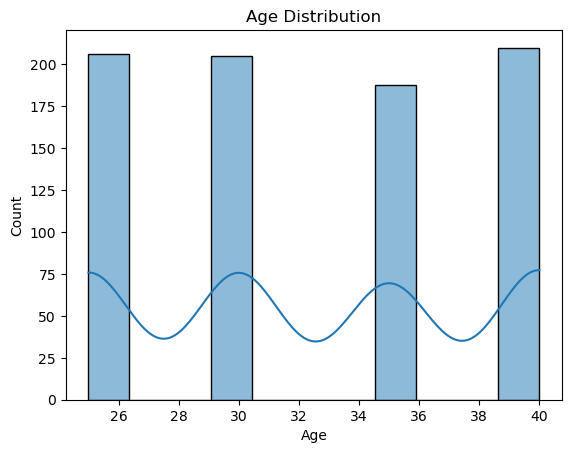

In [37]:
sns.histplot(df['Age'], kde=True)
plt.title('Age Distribution')
plt.show()

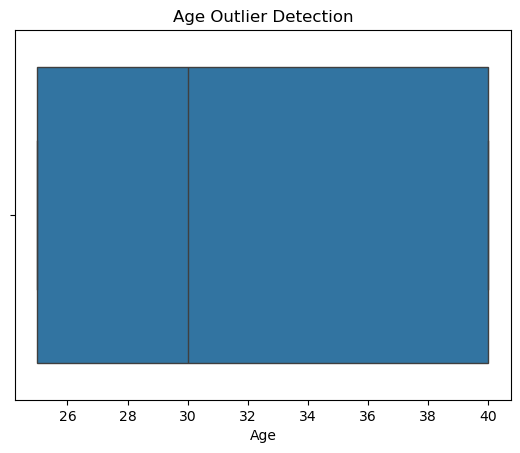

In [41]:
sns.boxplot(x=df['Age'])
plt.title('Age Outlier Detection')
plt.show()

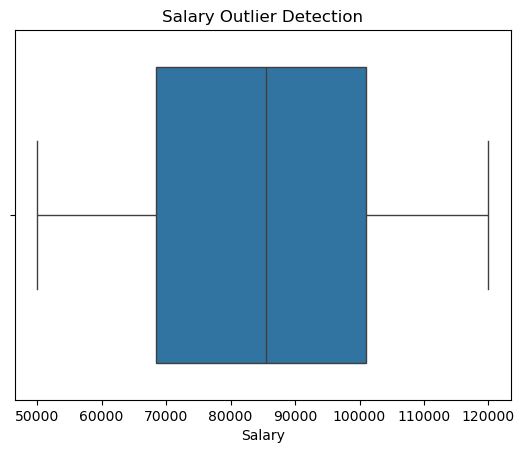

In [40]:
sns.boxplot(x=df['Salary'])
plt.title('Salary Outlier Detection')
plt.show()

In [42]:
# Check Age outliers
Q1_age = df['Age'].quantile(0.25)
Q3_age = df['Age'].quantile(0.75)
IQR_age = Q3_age - Q1_age

lower_age = Q1_age - 1.5 * IQR_age
upper_age = Q3_age + 1.5 * IQR_age

df[(df['Age'] < lower_age) | (df['Age'] > upper_age)]['Age'].sort_values()

Series([], Name: Age, dtype: float64)

In [46]:
# salary outlier

Q1_salary = df['Salary'].quantile(0.25)
Q3_salary = df['Salary'].quantile(0.75)
IQR_salary = Q3_salary - Q1_salary

lower_salary = Q1_salary - 1.5 * IQR_salary
upper_salary = Q3_salary + 1.5 * IQR_salary

df[(df['Salary'] < lower_salary) | (df['Salary'] > upper_salary)]['Salary'].sort_values()

Series([], Name: Salary, dtype: float64)

In [47]:
df['Age'].fillna(df['Age'].median(), inplace=True)

/var/folders/fj/l3h634j97r59hm0b4hf8y1x00000gn/T/ipykernel_65270/1933487976.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Age'].fillna(df['Age'].median(), inplace=True)


In [48]:
df['Age'].isnull().sum()

np.int64(0)

In [49]:
df['Salary'].fillna(df['Salary'].median(), inplace=True)

/var/folders/fj/l3h634j97r59hm0b4hf8y1x00000gn/T/ipykernel_65270/2984858743.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Salary'].fillna(df['Salary'].median(), inplace=True)


In [50]:
df['Salary'].isnull().sum()

np.int64(0)

In [52]:
# Remove extra spaces from text columns

In [53]:
text_columns = df.select_dtypes(include='object').columns

print(text_columns)

for col in text_columns:
    df[col] = df[col].str.strip()

Index(['Employee_ID', 'First_Name', 'Last_Name', 'Department_Region', 'Status',
       'Join_Date', 'Email', 'Performance_Score'],
      dtype='object')


In [56]:
# Standardize categorical columns


In [57]:
df['Status'] = df['Status'].str.title()
df['Performance_Score'] = df['Performance_Score'].str.title()
df['Department_Region'] = df['Department_Region'].str.title()

In [58]:
df['Status'].unique()
df['Performance_Score'].unique()

array(['Average', 'Excellent', 'Good', 'Poor'], dtype=object)

In [ ]:
#Join_Date ko DateTime format mein convert karna

In [59]:
df['Join_Date'] = pd.to_datetime(df['Join_Date'], errors='coerce')

In [60]:
df['Join_Date'].dtype

dtype('<M8[ns]')

In [61]:
df['Join_Date'].isnull().sum()

np.int64(0)

In [62]:
# Check invalid email addresses

In [63]:
df[~df['Email'].str.contains(r'^[\w\.-]+@[\w\.-]+\.\w+$', na=False)]

,Employee_ID,First_Name,Last_Name,Age,Department_Region,Status,Join_Date,Salary,Email,Phone,Performance_Score,Remote_Work


In [64]:
# Check phone number format

In [65]:
df[~df['Phone'].astype(str).str.match(r'^\d{10}$', na=False)]

,Employee_ID,First_Name,Last_Name,Age,Department_Region,Status,Join_Date,Salary,Email,Phone,Performance_Score,Remote_Work
0,EMP1000,Bob,Davis,25.0,Devops-California,Active,2021-04-02,59767.65,bob.davis@example.com,-1651623197,Average,True
1,EMP1001,Bob,Brown,30.0,Finance-Texas,Active,2020-07-10,65304.66,bob.brown@example.com,-1898471390,Excellent,True
2,EMP1002,Alice,Jones,30.0,Admin-Nevada,Pending,2023-12-07,88145.90,alice.jones@example.com,-5596363211,Good,True
3,EMP1003,Eva,Davis,25.0,Admin-Nevada,Inactive,2021-11-27,69450.99,eva.davis@example.com,-3476490784,Good,True
4,EMP1004,Frank,Williams,25.0,Cloud Tech-Florida,Active,2022-01-05,109324.61,frank.williams@example.com,-1586734256,Poor,False
...,...,...,...,...,...,...,...,...,...,...,...,...
1015,EMP2015,David,Miller,30.0,Hr-California,Active,2023-08-19,85547.87,david.miller@example.com,-3546212759,Good,True
1016,EMP2016,David,Johnson,30.0,Cloud Tech-Texas,Inactive,2021-11-07,100215.06,david.johnson@example.com,-2508261122,Good,True
1017,EMP2017,Charlie,Williams,40.0,Finance-New York,Active,2023-10-04,114587.11,charlie.williams@example.com,-1261632487,Average,False
1018,EMP2018,Alice,Garcia,30.0,Hr-Florida,Inactive,2024-12-16,71318.79,alice.garcia@example.com,-8995729892,Good,True


In [66]:
# Performance Score & Status verification

In [67]:
print("Status Values:")
print(df['Status'].value_counts())

print("\nPerformance Score Values:")
print(df['Performance_Score'].value_counts())

print("\nRemote Work Values:")
print(df['Remote_Work'].value_counts())

Status Values:
Status
Pending     356
Active      352
Inactive    312
Name: count, dtype: int64

Performance Score Values:
Performance_Score
Good         270
Average      267
Excellent    267
Poor         216
Name: count, dtype: int64

Remote Work Values:
Remote_Work
True     513
False    507
Name: count, dtype: int64


# Final Missing Values Verification

In [68]:
df.isnull().sum()

Employee_ID          0
First_Name           0
Last_Name            0
Age                  0
Department_Region    0
Status               0
Join_Date            0
Salary               0
Email                0
Phone                0
Performance_Score    0
Remote_Work          0
dtype: int64

In [69]:
df.isnull().sum().sum()

np.int64(0)

In [70]:
df.shape

(1020, 12)

In [71]:
df.head(|)

,Employee_ID,First_Name,Last_Name,Age,Department_Region,Status,Join_Date,Salary,Email,Phone,Performance_Score,Remote_Work
0,EMP1000,Bob,Davis,25.0,Devops-California,Active,2021-04-02,59767.65,bob.davis@example.com,-1651623197,Average,True
1,EMP1001,Bob,Brown,30.0,Finance-Texas,Active,2020-07-10,65304.66,bob.brown@example.com,-1898471390,Excellent,True
2,EMP1002,Alice,Jones,30.0,Admin-Nevada,Pending,2023-12-07,88145.90,alice.jones@example.com,-5596363211,Good,True
3,EMP1003,Eva,Davis,25.0,Admin-Nevada,Inactive,2021-11-27,69450.99,eva.davis@example.com,-3476490784,Good,True
4,EMP1004,Frank,Williams,25.0,Cloud Tech-Florida,Active,2022-01-05,109324.61,frank.williams@example.com,-1586734256,Poor,False


In [72]:
# Final Data Quality Check

In [73]:
print("Dataset Shape:", df.shape)

print("\nData Types:")
print(df.dtypes)

print("\nDuplicate Rows:", df.duplicated().sum())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nFirst 5 Cleaned Records:")
display(df.head())

Dataset Shape: (1020, 12)

Data Types:
Employee_ID                  object
First_Name                   object
Last_Name                    object
Age                         float64
Department_Region            object
Status                       object
Join_Date            datetime64[ns]
Salary                      float64
Email                        object
Phone                         int64
Performance_Score            object
Remote_Work                    bool
dtype: object

Duplicate Rows: 0

Missing Values:
Employee_ID          0
First_Name           0
Last_Name            0
Age                  0
Department_Region    0
Status               0
Join_Date            0
Salary               0
Email                0
Phone                0
Performance_Score    0
Remote_Work          0
dtype: int64

First 5 Cleaned Records:


,Employee_ID,First_Name,Last_Name,Age,Department_Region,Status,Join_Date,Salary,Email,Phone,Performance_Score,Remote_Work
0,EMP1000,Bob,Davis,25.0,Devops-California,Active,2021-04-02,59767.65,bob.davis@example.com,-1651623197,Average,True
1,EMP1001,Bob,Brown,30.0,Finance-Texas,Active,2020-07-10,65304.66,bob.brown@example.com,-1898471390,Excellent,True
2,EMP1002,Alice,Jones,30.0,Admin-Nevada,Pending,2023-12-07,88145.90,alice.jones@example.com,-5596363211,Good,True
3,EMP1003,Eva,Davis,25.0,Admin-Nevada,Inactive,2021-11-27,69450.99,eva.davis@example.com,-3476490784,Good,True
4,EMP1004,Frank,Williams,25.0,Cloud Tech-Florida,Active,2022-01-05,109324.61,frank.williams@example.com,-1586734256,Poor,False


In [74]:
df.to_csv('Cleaned_Employee_Dataset.csv', index=False)

In [75]:
df = pd.read_csv("Cleaned_Employee_Dataset.csv")
df.head()

,Employee_ID,First_Name,Last_Name,Age,Department_Region,Status,Join_Date,Salary,Email,Phone,Performance_Score,Remote_Work
0,EMP1000,Bob,Davis,25.0,Devops-California,Active,2021-04-02,59767.65,bob.davis@example.com,-1651623197,Average,True
1,EMP1001,Bob,Brown,30.0,Finance-Texas,Active,2020-07-10,65304.66,bob.brown@example.com,-1898471390,Excellent,True
2,EMP1002,Alice,Jones,30.0,Admin-Nevada,Pending,2023-12-07,88145.90,alice.jones@example.com,-5596363211,Good,True
3,EMP1003,Eva,Davis,25.0,Admin-Nevada,Inactive,2021-11-27,69450.99,eva.davis@example.com,-3476490784,Good,True
4,EMP1004,Frank,Williams,25.0,Cloud Tech-Florida,Active,2022-01-05,109324.61,frank.williams@example.com,-1586734256,Poor,False
